# پیش‌بینی احتمالی کوتاه‌مدت قیمت با پرایس اکشن و خط روند (نسخه ۲)

این نوت‌بوک پیاده‌سازی سند «طرح پیاده‌سازی» است. خروجی برای هر لحظه:

- **جدول احتمال برای بازه‌های درصدی** در H دقیقه آینده (پیش‌فرض ۷ دقیقه). مثلاً «۳۸٪ احتمال بین +0.12% و +0.36%».
- **سد سه‌گانه:** احتمال اینکه قیمت **اول** به حد سود برسد یا اول به حد ضرر (برای معامله با اهرم).

مدل‌ها (هر کدام یک «سبک تحلیل» = یک گروه ویژگی):

| مدل | ورودی |
|---|---|
| `M0` | فقط فراوانی تاریخی کلاس‌ها در همان رژیم نوسان (بدون ML) |
| `M1` | پایه: بازده، نوسان، حجم، جریان خرید/فروش taker، زمان |
| `M2` | پایه + **خط روند** (خط حمایت/مقاومت از pivotها، شکست، پولبک، کانال، EMA، ADX، شیب رگرسیون) |
| `M3` | پایه + **پرایس اکشن** (ساختار بازار HH/HL، BOS/CHoCH، نواحی حمایت/مقاومت، الگوهای کندلی، شکار استاپ، FVG، سقف/کف روز قبل، اعداد رند) |
| `M4` | همه |

ویژگی‌های تحلیل تکنیکال روی تایم‌فریم‌های **۵ دقیقه، ۱۵ دقیقه و ۱ ساعت** ساخته می‌شوند و فقط کندل‌های **بسته‌شده** استفاده می‌شوند.

**مراحل:** dev در ۲۰۲۴ (مقایسه هر ۴ سبک) ← اعتبارسنجی در ۲۰۲۵ (فقط ۲ برنده) ← **تست قفل** در ۲۰۲۶ روی ۵ ارز اصلی + **۶ ارزی که مدل هرگز ندیده**.

**اجرا:** `Runtime → Run all`. به GPU نیازی نیست. اجرای اول (دانلود داده دقیقه‌ای و ساخت ویژگی‌ها) حدود ۱ تا ۲ ساعت طول می‌کشد. بعد از آن همه چیز cache است. **حتماً `USE_DRIVE=True` بماند** تا اگر Colab قطع شد، کار از اول شروع نشود. به RAM بالا (High-RAM) هم نیاز است. اگر RAM کم آمد، `DATA_START` را جلوتر بیاورید یا `SAMPLE_EVERY` را بزرگ‌تر کنید.

In [1]:
%pip -q install "lightgbm>=4.3" pyarrow requests tqdm

## ۱) تنظیمات

In [2]:
import io, os, json, time, zipfile, hashlib, warnings, gc
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.optimize import minimize_scalar
from tqdm.auto import tqdm
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings('ignore')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', None)

# ---------------- coins & periods ----------------
DEV_COINS = ['BTC', 'ETH', 'SOL', 'BNB', 'XRP']               # used for training
NEW_COINS = ['ADA', 'DOGE', 'AVAX', 'LINK', 'LTC', 'TRX']      # never trained on; final test only
DATA_START = '2023-01'            # first month of 1m data for DEV_COINS (2023 = initial training history)
NEW_COINS_DATA_START = '2025-10'  # warm-up for new coins before the 2026 test
DEV_START, VAL_START, TEST_START = '2024-01-01', '2025-01-01', '2026-01-01'
FOLD_FREQ = 'QS'                  # retrain every quarter
RUN_FINAL_TEST = False            # set True ONCE at the very end
USE_DRIVE = False

# ---------------- target ----------------
HORIZON_MIN = 7                   # forecast horizon in minutes (try 15 / 60 too)
SAMPLE_EVERY = 5                  # keep one decision point every N minutes (memory)
TRAIN_EVERY = 3                   # train on every 3rd kept row (= every 15 min) to reduce overlap
Z_EDGES = [-1.5, -0.75, -0.25, 0.25, 0.75, 1.5]   # bucket edges in units of expected H-minute volatility
K_UP, K_DN = 1.0, 1.0             # triple-barrier take-profit / stop-loss in volatility units
VOL_SPAN_MIN = 240                # EWMA span (minutes) for the volatility used to scale targets

# ---------------- technical-analysis settings ----------------
TA_TFS = {'5min': 3, '15min': 3, '1h': 2}   # timeframe -> pivot half-window k
LINE_TOL = 0.2                    # a close more than 0.2 ATR beyond a line = violation / break
TOUCH_TOL = 0.25                  # within 0.25 ATR of a line = a touch
MAX_PIVOTS_LINE = 6               # pivots considered when fitting the best trendline
SR_PIVOTS = 40                    # pivots used to build support/resistance zones
SR_MERGE = 0.5                    # pivots closer than 0.5 ATR belong to the same zone

# ---------------- model ----------------
TRAIN_DAYS = 365                  # rolling training window
ES_DAYS = 30                      # last 30 days of the window (after an embargo) for early stopping
SEED = 42
LGB_PARAMS = dict(objective='multiclass', n_estimators=400, learning_rate=0.08, num_leaves=31,
                  min_child_samples=300, subsample=0.7, subsample_freq=1, colsample_bytree=0.5,
                  reg_lambda=5.0, max_bin=63, n_jobs=-1, random_state=SEED, verbose=-1)
TOP_ARMS_TO_VAL = 2

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        ROOT = Path('/content/drive/MyDrive/ta_prob_v2')
    except ImportError:
        ROOT = Path('ta_prob_v2')
else:
    ROOT = Path('/content/ta_prob_v2') if Path('/content').exists() else Path('ta_prob_v2')
RAW = ROOT / 'raw_1m'; FEAT = ROOT / 'features'; RES = ROOT / 'results'; PREDS = ROOT / 'preds'
for p in (RAW, FEAT, RES, PREDS):
    p.mkdir(parents=True, exist_ok=True)
TODAY = pd.Timestamp.now(tz='UTC').normalize()
N_CLASSES = len(Z_EDGES) + 1
print('root:', ROOT, '| today:', TODAY.date(), '| horizon:', HORIZON_MIN, 'min | classes:', N_CLASSES)

root: /content/ta_prob_v2 | today: 2026-11-19 | horizon: 7 min | classes: 7


## ۲) دانلود داده ۱ دقیقه‌ای بایننس

برای هر ماه یک ZIP از `data.binance.vision` دانلود و به Parquet تبدیل می‌شود (cache). ماه جاری از فایل‌های روزانه خوانده می‌شود. timestampهای ۲۰۲۵ به بعد میکروثانیه‌اند و خودکار تشخیص داده می‌شوند. **ایندکس هر کندل، زمان بسته‌شدن آن است** (open + 1 دقیقه)، یعنی لحظه‌ای که اطلاعات آن کندل واقعاً معلوم می‌شود.

In [3]:
BASE = 'https://data.binance.vision/data'
SESSION = requests.Session()
KCOLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time',
         'quote_volume', 'trades', 'taker_buy_base', 'taker_buy_quote', 'ignore']

def fetch(url, tries=5):
    for k in range(tries):
        try:
            r = SESSION.get(url, timeout=(20, 300))
            if r.status_code == 404:
                return None
            r.raise_for_status()
            return r.content
        except requests.RequestException:
            if k == tries - 1:
                raise
            time.sleep(2 ** k)

def read_kline_zip(payload):
    with zipfile.ZipFile(io.BytesIO(payload)) as z:
        name = [n for n in z.namelist() if n.endswith('.csv')][0]
        with z.open(name) as f:
            df = pd.read_csv(f, header=None, names=KCOLS, usecols=[0, 1, 2, 3, 4, 7, 8, 10], low_memory=False)
    df['open_time'] = pd.to_numeric(df['open_time'], errors='coerce')
    df = df.dropna(subset=['open_time'])
    t = df['open_time'].to_numpy(dtype=np.int64)
    t = np.where(t > 10**14, t // 1000, t)
    out = pd.DataFrame({
        'o': pd.to_numeric(df['open'], errors='coerce').to_numpy(),
        'h': pd.to_numeric(df['high'], errors='coerce').to_numpy(),
        'l': pd.to_numeric(df['low'], errors='coerce').to_numpy(),
        'c': pd.to_numeric(df['close'], errors='coerce').to_numpy(),
        'qv': pd.to_numeric(df['quote_volume'], errors='coerce').to_numpy(),
        'n': pd.to_numeric(df['trades'], errors='coerce').to_numpy(),
        'tbq': pd.to_numeric(df['taker_buy_quote'], errors='coerce').to_numpy(),
    }, index=pd.to_datetime(t, unit='ms', utc=True) + pd.Timedelta(minutes=1))   # index = close time
    out = out[(out[['o', 'h', 'l', 'c']] > 0).all(axis=1)]
    out = out[~out.index.duplicated(keep='last')].sort_index()
    out.index.name = 'ts'
    return out

def load_minutes(symbol, start_month):
    pair = symbol + 'USDT'
    months = pd.period_range(start_month, TODAY.strftime('%Y-%m'), freq='M')
    parts = []
    for mth in tqdm(months, desc=pair, leave=False):
        path = RAW / f'{pair}_{mth}.parquet'
        if path.exists():
            parts.append(pd.read_parquet(path)); continue
        payload = fetch(f'{BASE}/spot/monthly/klines/{pair}/1m/{pair}-1m-{mth}.zip')
        if payload is not None:
            d = read_kline_zip(payload); d.to_parquet(path); parts.append(d); continue
        if mth < months[-2]:
            continue                                   # not listed yet
        first = mth.start_time.tz_localize('UTC')
        last = min(mth.end_time.tz_localize('UTC').normalize(), TODAY - pd.Timedelta(days=1))
        for day in (pd.date_range(first, last, freq='D') if last >= first else []):
            dpath = RAW / f'{pair}_day_{day:%Y-%m-%d}.parquet'
            if dpath.exists():
                parts.append(pd.read_parquet(dpath)); continue
            pl = fetch(f'{BASE}/spot/daily/klines/{pair}/1m/{pair}-1m-{day:%Y-%m-%d}.zip')
            if pl is not None:
                d = read_kline_zip(pl); d.to_parquet(dpath); parts.append(d)
    m = pd.concat(parts)
    m = m[~m.index.duplicated(keep='last')].sort_index()
    grid = pd.date_range(m.index.min(), m.index.max(), freq='1min')
    m = m.reindex(grid)                                # missing minutes stay NaN (never invented)
    m.index.name = 'ts'
    return m

## ۳) برچسب‌ها و ویژگی‌های پایه (روی داده ۱ دقیقه‌ای)

**نوسان مرجع:** `sigma_H` = EWMA بازده‌های ۱ دقیقه‌ای (فقط گذشته) × √H.

**برچسب ۱، بازه:** `z = log(close[t+H]/close[t]) / sigma_H`، تقسیم‌شده به ۷ کلاس با مرزهای `Z_EDGES`. برای گزارش، مرزها در `sigma_H` همان لحظه ضرب و به درصد تبدیل می‌شوند.

**برچسب ۲، سد سه‌گانه:** `+1` اگر قیمت اول به `+K_UP·sigma_H` برسد، `−1` اگر اول به `−K_DN·sigma_H` برسد، و `0` اگر تا H دقیقه به هیچ‌کدام نرسد. اگر هر دو در **یک کندل** لمس شوند، ترتیب معلوم نیست و برچسب حذف می‌شود.

**ویژگی‌های پایه (گروه `b_`):** بازده‌های نرمال‌شده ۱ تا ۱۴۴۰ دقیقه، نوسان‌های محقق‌شده و نسبتشان، ATR، حجم و تعداد معاملات (z-score)، نسبت خرید taker، موقعیت در رنج، شکل کندل ۱ دقیقه‌ای و زمان روز و هفته.

In [4]:
def base_features_and_labels(m):
    H = HORIZON_MIN
    c, h, l, o = m['c'], m['h'], m['l'], m['o']
    lc, lh, ll = np.log(c), np.log(h), np.log(l)
    r1 = lc.diff()
    var1 = (r1 ** 2).ewm(span=VOL_SPAN_MIN, min_periods=60, ignore_na=True).mean()
    sig1 = np.sqrt(var1)
    sigH = sig1 * np.sqrt(H)
    f = pd.DataFrame(index=m.index)
    for w in (1, 3, 5, 15, 60, 240, 1440):
        f[f'b_ret_{w}'] = lc.diff(w) / (sig1 * np.sqrt(w))
    rv = {w: np.sqrt((r1 ** 2).rolling(w, min_periods=w // 2).mean()) for w in (15, 60, 240, 1440)}
    f['b_vol_level'] = np.log(sig1)
    f['b_vol_15_240'] = np.log(rv[15] / rv[240])
    f['b_vol_60_1440'] = np.log(rv[60] / rv[1440])
    tr = np.maximum(lh - ll, np.maximum((lh - lc.shift()).abs(), (ll - lc.shift()).abs()))
    f['b_atr_ratio'] = np.log(tr.ewm(span=14).mean() / sig1)
    lq, lt = np.log1p(m['qv']), np.log1p(m['n'])
    for w in (60, 1440):
        f[f'b_qv_z{w}'] = (lq - lq.rolling(w, min_periods=w // 2).mean()) / lq.rolling(w, min_periods=w // 2).std()
        f[f'b_trades_z{w}'] = (lt - lt.rolling(w, min_periods=w // 2).mean()) / lt.rolling(w, min_periods=w // 2).std()
    for w in (1, 5, 15, 60):
        f[f'b_taker_{w}'] = m['tbq'].rolling(w).sum() / m['qv'].rolling(w).sum() - 0.5
    for w in (60, 240, 1440):
        hi, lo = h.rolling(w, min_periods=w // 2).max(), l.rolling(w, min_periods=w // 2).min()
        f[f'b_rangepos_{w}'] = (c - lo) / (hi - lo)
    rng = (h - l).replace(0, np.nan)
    f['b_body'] = (c - o) / rng
    f['b_upwick'] = (h - np.maximum(o, c)) / rng
    f['b_lowick'] = (np.minimum(o, c) - l) / rng
    f['b_body_l1'] = f['b_body'].shift(1)
    mod = m.index.hour * 60 + m.index.minute
    f['b_tod_sin'], f['b_tod_cos'] = np.sin(2 * np.pi * mod / 1440), np.cos(2 * np.pi * mod / 1440)
    f['b_dow'] = m.index.dayofweek
    # ---------------- labels (future) ----------------
    ok_window = c.notna().astype(float).rolling(H).sum().shift(-H) == H
    rfwd = lc.shift(-H) - lc
    z = rfwd / sigH
    y_bucket = pd.Series(np.digitize(z.fillna(0), Z_EDGES), index=m.index).where(ok_window & z.notna())
    up, dn = (lc + K_UP * sigH).to_numpy(), (lc - K_DN * sigH).to_numpy()
    lhv, llv = lh.to_numpy(), ll.to_numpy()
    n = len(m)
    lab = np.zeros(n); done = np.zeros(n, bool); amb = np.zeros(n, bool)
    for j in range(1, H + 1):
        hj = np.full(n, np.nan); lj = np.full(n, np.nan)
        hj[:n - j], lj[:n - j] = lhv[j:], llv[j:]
        hu, hd = hj >= up, lj <= dn
        both = hu & hd & ~done
        amb |= both
        lab = np.where(~done & hu & ~hd, 1, np.where(~done & hd & ~hu, -1, lab))
        done |= hu | hd
    y_barrier = pd.Series(lab, index=m.index).where(ok_window & ~amb & sigH.notna())
    lab_df = pd.DataFrame({'y_bucket': y_bucket, 'y_barrier': y_barrier, 'sigH': sigH,
                           'close': c, 'rfwd': rfwd}, index=m.index)
    return f, lab_df

## ۴) ویژگی‌های خط روند و پرایس اکشن (روی کندل‌های ۵ دقیقه، ۱۵ دقیقه و ۱ ساعت)

برای هر تایم‌فریم، از کندل‌های ۱ دقیقه‌ای کندل بزرگ‌تر ساخته می‌شود (ایندکس = زمان بسته‌شدن). بعد یک حلقه زمانی (مثل تریدری که کندل به کندل جلو می‌رود) این‌ها را حساب می‌کند:

1. **Pivot:** سقف یا کفی که از k کندل هر طرف بالاتر یا پایین‌تر است. **فقط بعد از k کندل تأیید می‌شود** و قبل از آن استفاده نمی‌شود.
2. **بهترین خط روند:** از بین جفت‌های ۶ کف یا سقف اخیر، خطی که هیچ close بیش از ۰٫۲ ATR آن طرفش بسته نشده و بیشترین لمس را دارد. شکست خط، قدرت شکست (به ATR و حجم) و پولبک بعد از شکست هم ثبت می‌شوند.
3. **ساختار بازار:** HH/HL/LH/LL، روند ساختاری، BOS و CHoCH.
4. **نواحی حمایت/مقاومت:** خوشه‌بندی ۴۰ pivot اخیر، به‌اضافه قدرت هر ناحیه (تعداد لمس).
5. **شکار استاپ (sweep)** و **FVG**.
6. **الگوهای کندلی:** پین‌بار، انگالفینگ، اینساید/اوت‌ساید، دوجی، ماروبوزو، سه سرباز/کلاغ، و ترکیب آن‌ها با «مکان» (روی حمایت یا مقاومت).

سطوح (مثل قیمت خط روند) ذخیره می‌شوند و **فاصله تا آن‌ها در لحظه تصمیم با قیمت ۱ دقیقه‌ای فعلی** حساب می‌شود. برای خط روند، شیب خط تا لحظه فعلی ادامه داده می‌شود.

In [5]:
def resample_tf(m, tf):
    agg = m.resample(tf, label='right', closed='left').agg(
        {'o': 'first', 'h': 'max', 'l': 'min', 'c': 'last', 'qv': 'sum'})
    return agg.dropna(subset=['c'])

def best_line(pts, j, c, atr, kind):
    best, best_score = None, -np.inf
    for a in range(len(pts)):
        for b in range(a + 1, len(pts)):
            ia, ya = pts[a]; ib, yb = pts[b]
            slope = (yb - ya) / (ib - ia)
            seg = np.arange(ia, j + 1)
            line = ya + slope * (seg - ia)
            if kind == 'sup':
                viol = np.any(c[seg] < line - LINE_TOL * atr[seg])
            else:
                viol = np.any(c[seg] > line + LINE_TOL * atr[seg])
            if viol:
                continue
            xs = np.array([p[0] for p in pts[a:]]); ys = np.array([p[1] for p in pts[a:]])
            touches = int((np.abs(ys - (ya + slope * (xs - ia))) / atr[xs] < TOUCH_TOL).sum())
            score = touches + 0.5 * np.log(ib - ia + 1) - 0.01 * (j - ib)
            if score > best_score:
                best_score = score
                best = dict(ia=ia, ya=ya, slope=slope, touches=touches, ib=ib)
    return best

def sr_zones(prices, tol):
    p = np.sort(np.asarray(prices))
    if len(p) == 0:
        return []
    zones, cur = [], [p[0]]
    for x in p[1:]:
        if x - cur[-1] < tol:
            cur.append(x)
        else:
            zones.append(cur); cur = [x]
    zones.append(cur)
    return [(min(z), max(z), len(z)) for z in zones]

def ta_loop(b, k):
    """Event-driven pass over closed bars of one timeframe. Uses only information known at each bar."""
    h, l, c = np.log(b['h'].to_numpy()), np.log(b['l'].to_numpy()), np.log(b['c'].to_numpy())
    atr, vz = b['atr'].to_numpy(), b['vz'].to_numpy()
    n = len(c)
    win = 2 * k + 1
    hmax = pd.Series(h).rolling(win, center=True, min_periods=win).max().to_numpy()
    lmin = pd.Series(l).rolling(win, center=True, min_periods=win).min().to_numpy()
    conf_h, conf_l = np.full(n, -1), np.full(n, -1)
    for i in np.where(h == hmax)[0]:
        if i + k < n: conf_h[i + k] = i            # pivot at bar i becomes KNOWN at bar i+k
    for i in np.where(l == lmin)[0]:
        if i + k < n: conf_l[i + k] = i
    names = ['sup_val', 'sup_slope', 'sup_touch', 'sup_age', 'sup_since_touch',
             'res_val', 'res_slope', 'res_touch', 'res_age', 'res_since_touch',
             'brk_dn_since', 'brk_dn_str', 'brk_dn_vol', 'brk_up_since', 'brk_up_str', 'brk_up_vol',
             'retest_dn_since', 'retest_up_since',
             'ms_trend', 'hh_count', 'll_count', 'last_high', 'last_low', 'swing_retrace',
             'bos_up_since', 'bos_dn_since', 'choch_up_since', 'choch_dn_since',
             'sweep_hi_since', 'sweep_lo_since', 'sweep_depth',
             'sr_sup', 'sr_res', 'sr_sup_str', 'sr_res_str', 'sr_in_zone',
             'fvg_bull', 'fvg_bear', 'fvg_bull_n', 'fvg_bear_n']
    O = {k_: np.full(n, np.nan) for k_ in names}
    highs, lows, piv_all = [], [], []
    sup = res = brk_dn = brk_up = None
    last_hi = prev_hi = last_lo = prev_lo = None
    hh_cnt = ll_cnt = 0; trend = 0
    hi_broken = lo_broken = True
    ev = dict(bos_up=-10**9, bos_dn=-10**9, choch_up=-10**9, choch_dn=-10**9, sw_hi=-10**9, sw_lo=-10**9,
              brk_dn=-10**9, brk_up=-10**9, rt_dn=-10**9, rt_up=-10**9)
    sweep_depth = 0.0
    zones = []
    fb, fs = [], []
    for j in range(n):
        if not np.isfinite(atr[j]) or atr[j] <= 0:
            continue
        new_piv = False
        if conf_h[j] >= 0:
            i = conf_h[j]; highs.append((i, h[i])); highs = highs[-MAX_PIVOTS_LINE:]; piv_all.append(h[i]); new_piv = True
            prev_hi, last_hi = last_hi, h[i]
            hh_cnt = hh_cnt + 1 if (prev_hi is not None and last_hi > prev_hi) else 0
            hi_broken = False
            res = best_line(highs, j, c, atr, 'res') if len(highs) >= 2 else None
        if conf_l[j] >= 0:
            i = conf_l[j]; lows.append((i, l[i])); lows = lows[-MAX_PIVOTS_LINE:]; piv_all.append(l[i]); new_piv = True
            prev_lo, last_lo = last_lo, l[i]
            ll_cnt = ll_cnt + 1 if (prev_lo is not None and last_lo < prev_lo) else 0
            lo_broken = False
            sup = best_line(lows, j, c, atr, 'sup') if len(lows) >= 2 else None
        if new_piv:
            piv_all = piv_all[-SR_PIVOTS:]
            zones = sr_zones(piv_all, SR_MERGE * atr[j])
            if None not in (last_hi, prev_hi, last_lo, prev_lo):
                if last_hi > prev_hi and last_lo > prev_lo: trend = 1
                elif last_hi < prev_hi and last_lo < prev_lo: trend = -1
                else: trend = 0
        # ---- trendlines: value now, breaks, retests ----
        if sup is not None:
            v = sup['ya'] + sup['slope'] * (j - sup['ia'])
            if c[j] < v - LINE_TOL * atr[j]:
                brk_dn = dict(line=sup, bar=j); ev['brk_dn'] = j
                O['brk_dn_str'][j] = (v - c[j]) / atr[j]; O['brk_dn_vol'][j] = vz[j]
                sup = None
            else:
                O['sup_val'][j], O['sup_slope'][j] = v, sup['slope']
                O['sup_touch'][j], O['sup_age'][j], O['sup_since_touch'][j] = sup['touches'], j - sup['ia'], j - sup['ib']
        if res is not None:
            v = res['ya'] + res['slope'] * (j - res['ia'])
            if c[j] > v + LINE_TOL * atr[j]:
                brk_up = dict(line=res, bar=j); ev['brk_up'] = j
                O['brk_up_str'][j] = (c[j] - v) / atr[j]; O['brk_up_vol'][j] = vz[j]
                res = None
            else:
                O['res_val'][j], O['res_slope'][j] = v, res['slope']
                O['res_touch'][j], O['res_age'][j], O['res_since_touch'][j] = res['touches'], j - res['ia'], j - res['ib']
        if brk_dn is not None and j > brk_dn['bar']:
            L = brk_dn['line']; v = L['ya'] + L['slope'] * (j - L['ia'])
            if h[j] >= v - TOUCH_TOL * atr[j] and c[j] < v:
                ev['rt_dn'] = j
        if brk_up is not None and j > brk_up['bar']:
            L = brk_up['line']; v = L['ya'] + L['slope'] * (j - L['ia'])
            if l[j] <= v + TOUCH_TOL * atr[j] and c[j] > v:
                ev['rt_up'] = j
        # ---- market structure: BOS / CHoCH / sweeps ----
        if last_hi is not None:
            if not hi_broken and c[j] > last_hi:
                hi_broken = True
                ev['bos_up' if trend >= 0 else 'choch_up'] = j
            if h[j] > last_hi and c[j] < last_hi:
                ev['sw_hi'] = j; sweep_depth = (h[j] - last_hi) / atr[j]
        if last_lo is not None:
            if not lo_broken and c[j] < last_lo:
                lo_broken = True
                ev['bos_dn' if trend <= 0 else 'choch_dn'] = j
            if l[j] < last_lo and c[j] > last_lo:
                ev['sw_lo'] = j; sweep_depth = -(last_lo - l[j]) / atr[j]
        # ---- fair value gaps ----
        if j >= 2:
            if l[j] > h[j - 2]: fb.append((h[j - 2], l[j]))
            if h[j] < l[j - 2]: fs.append((h[j], l[j - 2]))
        fb = [g for g in fb if l[j] > g[0]][-10:]
        fs = [g for g in fs if h[j] < g[1]][-10:]
        # ---- write state ----
        O['ms_trend'][j], O['hh_count'][j], O['ll_count'][j] = trend, hh_cnt, ll_cnt
        O['last_high'][j] = last_hi if last_hi is not None else np.nan
        O['last_low'][j] = last_lo if last_lo is not None else np.nan
        if last_hi is not None and last_lo is not None and last_hi > last_lo:
            O['swing_retrace'][j] = (last_hi - c[j]) / (last_hi - last_lo)
        for key, name in (('brk_dn', 'brk_dn_since'), ('brk_up', 'brk_up_since'), ('rt_dn', 'retest_dn_since'),
                          ('rt_up', 'retest_up_since'), ('bos_up', 'bos_up_since'), ('bos_dn', 'bos_dn_since'),
                          ('choch_up', 'choch_up_since'), ('choch_dn', 'choch_dn_since'),
                          ('sw_hi', 'sweep_hi_since'), ('sw_lo', 'sweep_lo_since')):
            O[name][j] = min(j - ev[key], 500)
        O['sweep_depth'][j] = sweep_depth
        below = [z for z in zones if z[1] < c[j]]
        above = [z for z in zones if z[0] > c[j]]
        if below:
            z = max(below, key=lambda z: z[1]); O['sr_sup'][j], O['sr_sup_str'][j] = z[1], z[2]
        if above:
            z = min(above, key=lambda z: z[0]); O['sr_res'][j], O['sr_res_str'][j] = z[0], z[2]
        O['sr_in_zone'][j] = float(any(z[0] <= c[j] <= z[1] for z in zones))
        O['fvg_bull'][j] = max((g[1] for g in fb if g[1] <= c[j]), default=np.nan)
        O['fvg_bear'][j] = min((g[0] for g in fs if g[0] >= c[j]), default=np.nan)
        O['fvg_bull_n'][j], O['fvg_bear_n'][j] = len(fb), len(fs)
    return pd.DataFrame(O, index=b.index)

def candle_and_trend_features(b):
    o, h, l, c = b['o'], b['h'], b['l'], b['c']
    lc = np.log(c)
    rng = (h - l).replace(0, np.nan)
    f = pd.DataFrame(index=b.index)
    body = (c - o).abs() / rng
    up_w, lo_w, clv = (h - np.maximum(o, c)) / rng, (np.minimum(o, c) - l) / rng, (c - l) / rng
    po, pc, ph, pl = o.shift(), c.shift(), h.shift(), l.shift()
    pa = {
        'body': body, 'upwick': up_w, 'lowick': lo_w, 'clv': clv,
        'range_atr': np.log(h / l) / b['atr'],
        'hammer': ((lo_w >= .6) & (body <= .3) & (clv >= .6)).astype(float),
        'star': ((up_w >= .6) & (body <= .3) & (clv <= .4)).astype(float),
        'bull_engulf': ((pc < po) & (c > o) & (o <= pc) & (c >= po)).astype(float),
        'bear_engulf': ((pc > po) & (c < o) & (o >= pc) & (c <= po)).astype(float),
        'inside': ((h < ph) & (l > pl)).astype(float),
        'outside': ((h > ph) & (l < pl)).astype(float),
        'doji': (body <= .1).astype(float),
        'marubozu': (body >= .9).astype(float) * np.sign(c - o),
    }
    strong_up = ((c > o) & (body >= .6) & (c > pc)).astype(int)
    strong_dn = ((c < o) & (body >= .6) & (c < pc)).astype(int)
    pa['three_soldiers'] = (strong_up.rolling(3).sum() == 3).astype(float)
    pa['three_crows'] = (strong_dn.rolling(3).sum() == 3).astype(float)
    for k_, v in pa.items():
        f['p_' + k_] = v
    f['p_hammer_l1'], f['p_star_l1'] = f['p_hammer'].shift(), f['p_star'].shift()
    f['p_engulf_l1'] = (f['p_bull_engulf'] - f['p_bear_engulf']).shift()
    # simple trend indicators (trend group)
    atr = b['atr']
    for span in (20, 50, 200):
        ema = lc.ewm(span=span, min_periods=span // 2).mean()
        f[f't_ema{span}_dist'] = (lc - ema) / atr
        f[f't_ema{span}_slope'] = (ema - ema.shift(5)) / (5 * atr)
    x = pd.Series(np.arange(len(b), dtype=float), index=b.index)
    for w in (20, 60):
        mx, my = x.rolling(w).mean(), lc.rolling(w).mean()
        cov = (x * lc).rolling(w).mean() - mx * my
        vx = (x * x).rolling(w).mean() - mx ** 2
        vy = (lc * lc).rolling(w).mean() - my ** 2
        f[f't_reg{w}_slope'] = cov / vx / atr
        f[f't_reg{w}_r2'] = (cov ** 2 / (vx * vy)).clip(0, 1)
    up_move, dn_move = h.diff(), -l.diff()
    pdm = np.where((up_move > dn_move) & (up_move > 0), up_move, 0.0)
    ndm = np.where((dn_move > up_move) & (dn_move > 0), dn_move, 0.0)
    trr = np.maximum(h - l, np.maximum((h - c.shift()).abs(), (l - c.shift()).abs()))
    atr_abs = trr.ewm(alpha=1 / 14).mean()
    pdi = 100 * pd.Series(pdm, index=b.index).ewm(alpha=1 / 14).mean() / atr_abs
    ndi = 100 * pd.Series(ndm, index=b.index).ewm(alpha=1 / 14).mean() / atr_abs
    dx = 100 * (pdi - ndi).abs() / (pdi + ndi)
    f['t_adx'], f['t_di_diff'] = dx.ewm(alpha=1 / 14).mean(), (pdi - ndi) / 100
    return f

LEVEL_COLS = ['sup_val', 'res_val', 'last_high', 'last_low', 'sr_sup', 'sr_res', 'fvg_bull', 'fvg_bear']

def tf_features(m, tf, k):
    b = resample_tf(m, tf)
    lc = np.log(b['c'])
    tr = np.maximum(np.log(b['h'] / b['l']), np.maximum((np.log(b['h']) - lc.shift()).abs(),
                                                         (np.log(b['l']) - lc.shift()).abs()))
    b['atr'] = tr.ewm(span=14, min_periods=14).mean()
    lq = np.log1p(b['qv'])
    b['vz'] = (lq - lq.rolling(50, min_periods=20).mean()) / lq.rolling(50, min_periods=20).std()
    loop = ta_loop(b, k)
    ct = candle_and_trend_features(b)
    out = pd.concat([loop, ct], axis=1)
    out['atr'] = b['atr']
    out['close_log'] = lc
    # candle pattern x location (price-action group)
    near_sup = ((lc - out['sr_sup']) / b['atr'] < 0.5) | ((lc - out['sup_val']).abs() / b['atr'] < 0.5)
    near_res = ((out['sr_res'] - lc) / b['atr'] < 0.5) | ((out['res_val'] - lc).abs() / b['atr'] < 0.5)
    out['p_hammer_at_sup'] = out['p_hammer'] * near_sup
    out['p_star_at_res'] = out['p_star'] * near_res
    out['p_engulf_at_level'] = (out['p_bull_engulf'] * near_sup) - (out['p_bear_engulf'] * near_res)
    tf_min = pd.Timedelta(tf).total_seconds() / 60
    out['tf_close_time'] = out.index
    out['slope_per_min_sup'] = out['sup_slope'] / tf_min
    out['slope_per_min_res'] = out['res_slope'] / tf_min
    return out

TREND_LOOP = ['sup_touch', 'sup_age', 'sup_since_touch', 'res_touch', 'res_age', 'res_since_touch',
              'brk_dn_since', 'brk_dn_str', 'brk_dn_vol', 'brk_up_since', 'brk_up_str', 'brk_up_vol',
              'retest_dn_since', 'retest_up_since']
PA_LOOP = ['ms_trend', 'hh_count', 'll_count', 'swing_retrace', 'bos_up_since', 'bos_dn_since',
           'choch_up_since', 'choch_dn_since', 'sweep_hi_since', 'sweep_lo_since', 'sweep_depth',
           'sr_sup_str', 'sr_res_str', 'sr_in_zone', 'fvg_bull_n', 'fvg_bear_n']

def attach_tf(rows, tf_out, tf):
    """rows: decision timestamps with current 1m log close. As-of join: only TF bars closed at or before t."""
    tag = tf.replace('min', 'm')
    keep = (TREND_LOOP + PA_LOOP + LEVEL_COLS + ['atr', 'tf_close_time', 'slope_per_min_sup', 'slope_per_min_res', 'sup_slope', 'res_slope']
            + [c_ for c_ in tf_out.columns if c_.startswith(('p_', 't_'))])
    right = tf_out[keep].copy()
    right['key'] = tf_out.index
    right = right.reset_index(drop=True).sort_values('key')
    j = pd.merge_asof(rows[['lc']].reset_index(), right, left_on='ts', right_on='key', direction='backward')
    j.index = rows.index
    atr = j['atr']
    dt = (j['ts'] - j['tf_close_time']).dt.total_seconds() / 60
    lc = j['lc']
    f = pd.DataFrame(index=rows.index)
    sup_now = j['sup_val'] + j['slope_per_min_sup'] * dt
    res_now = j['res_val'] + j['slope_per_min_res'] * dt
    f[f't_{tag}_sup_dist'] = (lc - sup_now) / atr
    f[f't_{tag}_res_dist'] = (res_now - lc) / atr
    f[f't_{tag}_sup_slope'] = j['sup_slope'] / atr
    f[f't_{tag}_res_slope'] = j['res_slope'] / atr
    width = res_now - sup_now
    f[f't_{tag}_ch_pos'] = ((lc - sup_now) / width).where(width > 0)
    f[f't_{tag}_ch_width'] = (width / atr).where(width > 0)
    for c_ in TREND_LOOP:
        f[f't_{tag}_{c_}'] = j[c_]
    for c_ in PA_LOOP:
        f[f'p_{tag}_{c_}'] = j[c_]
    f[f'p_{tag}_dist_last_high'] = (j['last_high'] - lc) / atr
    f[f'p_{tag}_dist_last_low'] = (lc - j['last_low']) / atr
    f[f'p_{tag}_sr_sup_dist'] = (lc - j['sr_sup']) / atr
    f[f'p_{tag}_sr_res_dist'] = (j['sr_res'] - lc) / atr
    f[f'p_{tag}_sr_room'] = np.log((f[f'p_{tag}_sr_res_dist'] + 0.1) / (f[f'p_{tag}_sr_sup_dist'] + 0.1))
    f[f'p_{tag}_fvg_bull_dist'] = (lc - j['fvg_bull']) / atr
    f[f'p_{tag}_fvg_bear_dist'] = (j['fvg_bear'] - lc) / atr
    for c_ in [c_ for c_ in tf_out.columns if c_.startswith(('p_', 't_'))]:
        grp, name = c_.split('_', 1)
        f[f'{grp}_{tag}_{name}'] = j[c_]
    return f

def daily_level_features(m, rows):
    """Previous UTC day high/low, today's open, round numbers (price-action group)."""
    d = m.resample('1D', label='left', closed='left').agg({'o': 'first', 'h': 'max', 'l': 'min'})
    prev = d[['h', 'l']].shift(1)                     # yesterday's range, known all of today
    day = (rows.index - pd.Timedelta(minutes=1)).floor('D')   # the day the 1m candle belongs to
    ph, pl = prev['h'].reindex(day).to_numpy(), prev['l'].reindex(day).to_numpy()
    dopen = d['o'].reindex(day).to_numpy()
    p = np.exp(rows['lc'].to_numpy())
    atr = rows['atr1'].to_numpy()
    f = pd.DataFrame(index=rows.index)
    f['p_prevday_high_dist'] = np.log(ph / p) / atr
    f['p_prevday_low_dist'] = np.log(p / pl) / atr
    f['p_dayopen_dist'] = np.log(p / dopen) / atr
    step = 10.0 ** (np.floor(np.log10(p)) - 1)
    rem = np.mod(p, step)
    f['p_round_dist'] = np.log1p(np.minimum(rem, step - rem) / p) / atr
    return f

def build_coin(symbol, start_month):
    path = FEAT / f'{symbol}_H{HORIZON_MIN}_S{SAMPLE_EVERY}.parquet'
    if path.exists():
        return pd.read_parquet(path)
    t0 = time.time()
    m = load_minutes(symbol, start_month)
    out = make_features(m)
    out['coin'] = symbol
    out.to_parquet(path)
    print(f'{symbol}: {len(out):,} rows, {sum(c_[:2] in ("b_", "t_", "p_") for c_ in out.columns)} features, '
          f'{time.time() - t0:.0f}s', flush=True)
    del m; gc.collect()
    return out

def make_features(m, with_labels=True):
    base, labels = base_features_and_labels(m)
    keep = m.index[(m.index.minute % SAMPLE_EVERY == 0) & m['c'].notna().to_numpy()]
    rows = pd.DataFrame(index=keep)
    rows['lc'] = np.log(m.loc[keep, 'c'])
    lc = np.log(m['c'])
    tr1 = np.maximum(np.log(m['h'] / m['l']), (np.log(m['h']) - lc.shift()).abs())
    rows['atr1'] = tr1.ewm(span=60, min_periods=30).mean().reindex(keep)
    parts = [base.reindex(keep)] + ([labels.reindex(keep)] if with_labels else []) + [daily_level_features(m, rows)]
    for tf, k in TA_TFS.items():
        parts.append(attach_tf(rows, tf_features(m, tf, k), tf))
    out = pd.concat(parts, axis=1)
    out = out.replace([np.inf, -np.inf], np.nan)
    fcols = [c_ for c_ in out.columns if c_[:2] in ('b_', 't_', 'p_')]
    out[fcols] = out[fcols].astype('float32')
    out.index.name = 'ts'
    return out

## ۵) ساخت ویژگی‌ها برای همه ارزها (کند، فقط بار اول)

هر ارز یک بار پردازش و در Parquet ذخیره می‌شود. اگر Colab قطع شد، دوباره Run all بزنید. ارزهای تمام‌شده از cache خوانده می‌شوند. ارزهای جدید (برای تست نهایی) فقط وقتی `RUN_FINAL_TEST=True` باشد ساخته می‌شوند.

In [6]:
DATA = pd.concat([build_coin(s, DATA_START) for s in DEV_COINS]).reset_index()
NEW = (pd.concat([build_coin(s, NEW_COINS_DATA_START) for s in NEW_COINS]).reset_index()
       if RUN_FINAL_TEST else None)
B = [c for c in DATA.columns if c.startswith('b_')]
T = [c for c in DATA.columns if c.startswith('t_')]
P = [c for c in DATA.columns if c.startswith('p_')]
ARMS = {'M1': B, 'M2': B + T, 'M3': B + P, 'M4': B + T + P}
print(f'rows={len(DATA):,} | base={len(B)} trend={len(T)} price-action={len(P)} features')
print('label balance (bucket):', DATA['y_bucket'].value_counts(normalize=True).sort_index().round(3).to_dict())
print('label balance (barrier):', DATA['y_barrier'].value_counts(normalize=True).sort_index().round(3).to_dict())

BTCUSDT:   0%|          | 0/47 [00:00<?, ?it/s]

BTC: 408,368 rows, 261 features, 158s


ETHUSDT:   0%|          | 0/47 [00:00<?, ?it/s]

ETH: 408,368 rows, 261 features, 148s


SOLUSDT:   0%|          | 0/47 [00:00<?, ?it/s]

SOL: 408,367 rows, 261 features, 151s


BNBUSDT:   0%|          | 0/47 [00:00<?, ?it/s]

BNB: 408,368 rows, 261 features, 159s


XRPUSDT:   0%|          | 0/47 [00:00<?, ?it/s]

XRP: 408,368 rows, 261 features, 154s
rows=2,041,839 | base=29 trend=96 price-action=136 features
label balance (bucket): {0.0: 0.056, 1.0: 0.134, 2.0: 0.191, 3.0: 0.236, 4.0: 0.194, 5.0: 0.135, 6.0: 0.054}
label balance (barrier): {-1.0: 0.239, 0.0: 0.533, 1.0: 0.228}


## ۶) تست ضدنشت آینده

ویژگی‌ها یک بار با داده کامل و یک بار با داده بریده‌شده در لحظه t ساخته می‌شوند. مقدار ویژگی‌ها در t **باید دقیقاً یکسان باشد.** اگر نباشد، یعنی جایی از آینده استفاده شده و نوت‌بوک متوقف می‌شود.

In [7]:
def leakage_test(symbol='BTC', days=12, n_checks=8, seed=0):
    m_all = load_minutes(symbol, (TODAY - pd.Timedelta(days=40)).strftime('%Y-%m'))
    m = m_all.iloc[-days * 1440:]
    full = make_features(m, with_labels=False)
    rng = np.random.default_rng(seed)
    cuts = rng.integers(len(m) // 2, len(m) - 10, n_checks)
    for cut in cuts:
        part = make_features(m.iloc[:cut + 1], with_labels=False)
        common = part.index.intersection(full.index)
        if len(common) == 0:
            continue
        t = common[-1]
        a, b = full.loc[t], part.loc[t]
        bad = ~np.isclose(a.to_numpy(float), b.to_numpy(float), equal_nan=True, rtol=1e-4, atol=1e-6)
        assert not bad.any(), f'LOOK-AHEAD at {t}: {list(a.index[bad])[:10]}'
    print(f'leakage test passed on {n_checks} random cut points ({symbol}, {days} days)')

leakage_test()

BTCUSDT:   0%|          | 0/2 [00:00<?, ?it/s]

leakage test passed on 8 random cut points (BTC, 12 days)


## ۷) آموزش walk-forward

برای هر فصل:

- **آموزش:** ۳۶۵ روز قبل از فصل، به‌جز ۳۰ روز آخر. هر ۱۵ دقیقه یک نمونه برداشته می‌شود تا نمونه‌ها کمتر روی هم بیفتند.
- **Early stopping و کالیبراسیون (temperature scaling):** ۳۰ روز آخر، با فاصله (embargo) از train و از شروع فصل.
- **M0:** فراوانی کلاس‌ها در ۵ رژیم نوسان، از همان داده train.

فقط ۵ ارز اصلی در آموزش هستند و ارزهای جدید هیچ‌وقت دیده نمی‌شوند.

In [8]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def fit_temperature(p, y):
    lp = np.log(np.clip(p, 1e-9, 1))
    nll = lambda t: -np.mean(np.log(softmax(lp / t)[np.arange(len(y)), y] + 1e-12))
    return minimize_scalar(nll, bounds=(0.5, 3.0), method='bounded').x

def y_of(frame, target):
    y = frame[target]
    return (y + 1) if target == 'y_barrier' else y          # barrier -1/0/1 -> 0/1/2

def n_cls(target):
    return N_CLASSES if target == 'y_bucket' else 3

def train_window(fold_start):
    gap = pd.Timedelta(minutes=HORIZON_MIN) + pd.Timedelta(hours=1)
    es_start = fold_start - pd.Timedelta(days=ES_DAYS)
    ts = DATA['ts']
    thin = (ts.dt.minute % (SAMPLE_EVERY * TRAIN_EVERY) == 0)
    tr = (ts >= fold_start - pd.Timedelta(days=TRAIN_DAYS)) & (ts < es_start - gap) & thin
    es = (ts >= es_start) & (ts < fold_start - gap) & thin
    return tr.to_numpy().copy(), es.to_numpy().copy()

def fit_models(arm, target, fold_start):
    cols = ARMS[arm]
    tr, es = train_window(fold_start)
    y = y_of(DATA, target)
    tr &= y.notna().to_numpy(); es &= y.notna().to_numpy()
    ytr, yes = y[tr].astype(int).to_numpy(), y[es].astype(int).to_numpy()
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(DATA.loc[tr, cols], ytr, eval_set=[(DATA.loc[es, cols], yes)],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    temp = fit_temperature(model.predict_proba(DATA.loc[es, cols]), yes)
    # M0: class frequencies per volatility regime (quintiles of b_vol_15_240) in the training window
    reg = DATA.loc[tr, 'b_vol_15_240']
    edges = np.nanquantile(reg, [0.2, 0.4, 0.6, 0.8])
    bins = np.digitize(reg.fillna(0), edges)
    freq = np.ones((5, n_cls(target)))
    np.add.at(freq, (bins, ytr), 1)
    freq /= freq.sum(axis=1, keepdims=True)
    return dict(model=model, temp=temp, cols=cols, m0_edges=edges, m0_freq=freq,
                best_iter=model.best_iteration_, n_train=int(tr.sum()))

def predict(fm, frame, rows):
    X = frame.loc[rows, fm['cols']]
    p = softmax(np.log(np.clip(fm['model'].predict_proba(X), 1e-9, 1)) / fm['temp'])
    b = np.digitize(frame.loc[rows, 'b_vol_15_240'].fillna(0), fm['m0_edges'])
    return p, fm['m0_freq'][b]

PRED = {}           # (frame_name, arm, target) -> (n_rows, n_classes) probabilities
LAST_MODEL = {}

def to_ts(x):
    x = pd.Timestamp(x)
    return x.tz_localize('UTC') if x.tzinfo is None else x

def run_period(arms, start, end, frames):
    start, end = to_ts(start), to_ts(end)
    folds = list(pd.date_range(start, end, freq=FOLD_FREQ))
    if not folds or folds[0] > start:
        folds = [start] + folds
    ends = folds[1:] + [end]
    for arm in arms:
        for target in ('y_bucket', 'y_barrier'):
            for fname, frame in frames.items():
                for key in ((fname, arm, target), (fname, 'M0', target)):
                    if key not in PRED:
                        PRED[key] = np.full((len(frame), n_cls(target)), np.nan)
            for fs, fe in zip(folds, ends):
                if fs >= fe:
                    continue
                t0 = time.time()
                fm = fit_models(arm, target, fs)
                LAST_MODEL[(arm, target)] = fm
                for fname, frame in frames.items():
                    rows = ((frame['ts'] >= fs) & (frame['ts'] < fe)).to_numpy()
                    if rows.any():
                        p, p0 = predict(fm, frame, rows)
                        PRED[(fname, arm, target)][rows] = p
                        PRED[(fname, 'M0', target)][rows] = p0
                print(f'{arm} {target:9s} fold {fs.date()}: trees={fm["best_iter"]}, T={fm["temp"]:.2f}, '
                      f'train={fm["n_train"]:,} ({time.time() - t0:.0f}s)', flush=True)

## ۸) معیارهای ارزیابی

- **Log loss و Skill نسبت به M0:** معیار اصلی است. `skill = 1 − LL_model / LL_M0`. مثبت یعنی مدل از «فراوانی تاریخی» بهتر است. فاصله اطمینان ۹۵٪ با bootstrap روی روزها حساب می‌شود.
- **جدول «وقتی مدل گفت X٪»:** برای آستانه‌های ثابت و همچنین برای «۱۰٪، ۵٪ و ۱٪ از مطمئن‌ترین پیش‌بینی‌ها» نشان می‌دهد مدل **چند درصد وقت‌ها** چنین سیگنالی داده و **چند درصد این سیگنال‌ها درست درآمده**. این همان معیاری است که بخش معاملات لازم دارد. نرخ پایه (بدون مدل) هم کنارش هست.
- **کالیبراسیون:** احتمال پیش‌بینی‌شده در برابر فراوانی واقعی.

In [9]:
UP = list(range(len(Z_EDGES) // 2 + 1, N_CLASSES))      # buckets above +edge
DN = list(range(0, len(Z_EDGES) // 2))                   # buckets below -edge

def eval_table(fname, frame, arms, mask, label):
    rows = []
    for target in ('y_bucket', 'y_barrier'):
        y = y_of(frame, target).to_numpy()
        m = mask & np.isfinite(y)
        for arm in arms + ['M0']:
            m &= np.isfinite(PRED[(fname, arm, target)]).all(axis=1)
        if m.sum() == 0:
            continue
        yi = y[m].astype(int)
        day = frame.loc[m, 'ts'].dt.floor('D').to_numpy()
        ll0 = -np.log(PRED[(fname, 'M0', target)][m][np.arange(m.sum()), yi] + 1e-12)
        d0 = pd.Series(ll0).groupby(day).mean()
        for arm in arms + ['M0']:
            p = PRED[(fname, arm, target)][m]
            ll = -np.log(p[np.arange(m.sum()), yi] + 1e-12)
            onehot = np.eye(p.shape[1])[yi]
            d = pd.Series(ll).groupby(day).mean()
            diff = (d - d0).to_numpy()
            rng = np.random.default_rng(SEED)
            boots = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(1000)]
            lo, hi = np.percentile(boots, [2.5, 97.5])
            rows.append({'period': label, 'target': target, 'model': arm, 'rows': int(m.sum()),
                         'logloss': ll.mean(), 'brier': ((p - onehot) ** 2).sum(axis=1).mean(),
                         'skill_vs_M0_%': 100 * (1 - ll.mean() / ll0.mean()),
                         'skill_CI95_%': 'reference' if arm == 'M0' else
                         f'[{-100 * hi / ll0.mean():.2f}, {-100 * lo / ll0.mean():.2f}]'})
    return pd.DataFrame(rows)

def signal_table(fname, frame, arm, mask, label):
    out = []
    for target in ('y_bucket', 'y_barrier'):
        y = y_of(frame, target).to_numpy()
        p = PRED[(fname, arm, target)]
        m = mask & np.isfinite(y) & np.isfinite(p).all(axis=1)
        y, p = y[m].astype(int), p[m]
        if target == 'y_bucket':
            sides = {'up (z>+0.25)': (p[:, UP].sum(1), np.isin(y, UP)), 'down (z<-0.25)': (p[:, DN].sum(1), np.isin(y, DN))}
        else:
            sides = {'TP first': (p[:, 2], y == 2), 'SL first': (p[:, 0], y == 0)}
        for side, (prob, hit) in sides.items():
            fixed = [0.40, 0.45, 0.50, 0.55, 0.60] if target == 'y_bucket' else [0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
            tops = {f'top {int(q * 100)}%': np.quantile(prob, 1 - q) for q in (0.10, 0.05, 0.01)}
            for name, thr in [(f'>= {t:.2f}', t) for t in fixed] + list(tops.items()):
                s = prob >= thr
                out.append({'period': label, 'target': target, 'side': side, 'rule': name, 'threshold': thr,
                            'base_rate': hit.mean(), 'signal_share_%': 100 * s.mean(),
                            'n_signals': int(s.sum()),
                            'hit_rate': hit[s].mean() if s.any() else np.nan,
                            'mean_predicted': prob[s].mean() if s.any() else np.nan})
    return pd.DataFrame(out)

def calibration_plot(fname, frame, arm, mask, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, target in zip(axes, ('y_bucket', 'y_barrier')):
        y = y_of(frame, target).to_numpy(); p = PRED[(fname, arm, target)]
        m = mask & np.isfinite(y) & np.isfinite(p).all(axis=1)
        y, p = y[m].astype(int), p[m]
        prob, hit = (p[:, UP].sum(1), np.isin(y, UP)) if target == 'y_bucket' else (p[:, 2], y == 2)
        bins = np.quantile(prob, np.linspace(0, 1, 11))
        idx = np.clip(np.digitize(prob, bins[1:-1]), 0, 9)
        pm = [prob[idx == i].mean() for i in range(10)]; hm = [hit[idx == i].mean() for i in range(10)]
        ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.plot(pm, hm, 'o-')
        lo, hi = min(pm + hm) - .05, max(pm + hm) + .05
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.grid(alpha=.3)
        ax.set_title(f'{title} | {arm} | ' + ('P(up)' if target == 'y_bucket' else 'P(TP first)'))
        ax.set_xlabel('predicted'); ax.set_ylabel('realized')
    plt.tight_layout(); plt.show()

LOG = ROOT / 'experiment_log.jsonl'
def log_run(kind, payload):
    with open(LOG, 'a') as fh:
        fh.write(json.dumps({'time': str(pd.Timestamp.now(tz='UTC')), 'kind': kind,
                             'horizon': HORIZON_MIN, **payload}, default=str) + '\n')

## ۹) مرحله dev (۲۰۲۴): مقایسه هر ۴ سبک

این کندترین بخش آموزش است: ۴ سبک × ۲ هدف × ۴ فصل.

In [10]:
FR = {'dev': DATA}
dev_mask = ((DATA['ts'] >= pd.Timestamp(DEV_START, tz='UTC')) & (DATA['ts'] < pd.Timestamp(VAL_START, tz='UTC'))).to_numpy()
run_period(list(ARMS), DEV_START, VAL_START, FR)
DEV_EVAL = eval_table('dev', DATA, list(ARMS), dev_mask, 'dev')
display(DEV_EVAL.round(4))
dev_score = DEV_EVAL[DEV_EVAL.model != 'M0'].groupby('model')['skill_vs_M0_%'].mean().sort_values(ascending=False)
print('mean dev skill vs M0 (%):'); print(dev_score.round(3).to_string())
TO_VAL = list(dev_score.index[:TOP_ARMS_TO_VAL])
print('\narms promoted to validation:', TO_VAL)
log_run('dev', {'skill': dev_score.round(4).to_dict(), 'promoted': TO_VAL})

M1 y_bucket  fold 2024-01-01: trees=46, T=1.17, train=160,725 (21s)
M1 y_bucket  fold 2024-04-01: trees=47, T=1.26, train=160,780 (20s)
M1 y_bucket  fold 2024-07-01: trees=69, T=1.09, train=160,780 (27s)
M1 y_bucket  fold 2024-10-01: trees=67, T=1.00, train=160,780 (24s)
M1 y_barrier fold 2024-01-01: trees=115, T=1.14, train=160,556 (17s)
M1 y_barrier fold 2024-04-01: trees=146, T=1.17, train=160,657 (19s)
M1 y_barrier fold 2024-07-01: trees=183, T=1.07, train=160,701 (23s)
M1 y_barrier fold 2024-10-01: trees=172, T=1.00, train=160,691 (19s)
M2 y_bucket  fold 2024-01-01: trees=60, T=1.17, train=160,725 (64s)
M2 y_bucket  fold 2024-04-01: trees=42, T=1.22, train=160,780 (47s)
M2 y_bucket  fold 2024-07-01: trees=72, T=1.10, train=160,780 (68s)
M2 y_bucket  fold 2024-10-01: trees=70, T=1.00, train=160,780 (66s)
M2 y_barrier fold 2024-01-01: trees=149, T=1.12, train=160,556 (47s)
M2 y_barrier fold 2024-04-01: trees=85, T=1.12, train=160,657 (30s)
M2 y_barrier fold 2024-07-01: trees=126, T=

,period,target,model,rows,logloss,brier,skill_vs_M0_%,skill_CI95_%
0,dev,y_bucket,M1,527040,1.8196,0.8254,0.5394,"[0.49, 0.59]"
1,dev,y_bucket,M2,527040,1.8198,0.8255,0.5300,"[0.48, 0.58]"
2,dev,y_bucket,M3,527040,1.8195,0.8253,0.5453,"[0.50, 0.60]"
3,dev,y_bucket,M4,527040,1.8194,0.8253,0.5492,"[0.50, 0.60]"
4,dev,y_bucket,M0,527040,1.8295,0.8274,0.0000,reference
5,dev,y_barrier,M1,526841,0.9801,0.5826,2.0036,"[1.89, 2.12]"
6,dev,y_barrier,M2,526841,0.9788,0.5817,2.1352,"[2.01, 2.26]"
7,dev,y_barrier,M3,526841,0.9785,0.5816,2.1612,"[2.04, 2.29]"
8,dev,y_barrier,M4,526841,0.9780,0.5812,2.2185,"[2.09, 2.34]"
9,dev,y_barrier,M0,526841,1.0001,0.5961,0.0000,reference


mean dev skill vs M0 (%):
model
M4    1.384
M3    1.353
M2    1.333
M1    1.272

arms promoted to validation: ['M4', 'M3']


## ۱۰) اعتبارسنجی (۲۰۲۵): فقط برنده‌های dev

M4 y_bucket  fold 2025-01-01: trees=60, T=1.13, train=160,780 (155s)
M4 y_bucket  fold 2025-04-01: trees=69, T=1.13, train=160,780 (163s)
M4 y_bucket  fold 2025-07-01: trees=54, T=1.07, train=160,780 (145s)
M4 y_bucket  fold 2025-10-01: trees=61, T=1.02, train=160,780 (150s)
M4 y_barrier fold 2025-01-01: trees=153, T=1.07, train=160,697 (109s)
M4 y_barrier fold 2025-04-01: trees=174, T=1.04, train=160,695 (116s)
M4 y_barrier fold 2025-07-01: trees=162, T=1.03, train=160,686 (113s)
M4 y_barrier fold 2025-10-01: trees=191, T=0.98, train=160,695 (125s)
M3 y_bucket  fold 2025-01-01: trees=75, T=1.15, train=160,780 (112s)
M3 y_bucket  fold 2025-04-01: trees=61, T=1.13, train=160,780 (101s)
M3 y_bucket  fold 2025-07-01: trees=47, T=1.04, train=160,780 (89s)
M3 y_bucket  fold 2025-10-01: trees=47, T=0.98, train=160,780 (89s)
M3 y_barrier fold 2025-01-01: trees=152, T=1.07, train=160,697 (71s)
M3 y_barrier fold 2025-04-01: trees=146, T=1.04, train=160,695 (69s)
M3 y_barrier fold 2025-07-01: tr

,period,target,model,rows,logloss,brier,skill_vs_M0_%,skill_CI95_%
0,val,y_bucket,M4,525600,1.8360,0.8299,0.3364,"[0.29, 0.38]"
1,val,y_bucket,M3,525600,1.8354,0.8297,0.3693,"[0.33, 0.41]"
2,val,y_bucket,M0,525600,1.8422,0.8310,0.0000,reference
3,val,y_barrier,M4,525388,0.9980,0.5952,1.8699,"[1.76, 2.00]"
4,val,y_barrier,M3,525388,0.9977,0.5950,1.9060,"[1.79, 2.03]"
5,val,y_barrier,M0,525388,1.0171,0.6082,0.0000,reference


CHOSEN (validation): M3 | mean skill vs M0 = 1.138%

"When the model said >= threshold, how often was it right?" (validation 2025)


,period,target,side,rule,threshold,base_rate,signal_share_%,n_signals,hit_rate,mean_predicted
0,val,y_bucket,up (z>+0.25),>= 0.40,0.400,0.388,52.390,275361,0.409,0.434
1,val,y_bucket,up (z>+0.25),>= 0.45,0.450,0.388,12.352,64924,0.442,0.477
2,val,y_bucket,up (z>+0.25),>= 0.50,0.500,0.388,1.939,10189,0.477,0.523
3,val,y_bucket,up (z>+0.25),>= 0.55,0.550,0.388,0.221,1164,0.486,0.571
4,val,y_bucket,up (z>+0.25),>= 0.60,0.600,0.388,0.022,118,0.559,0.618
5,val,y_bucket,up (z>+0.25),top 10%,0.456,0.388,10.000,52560,0.447,0.483
6,val,y_bucket,up (z>+0.25),top 5%,0.476,0.388,5.000,26280,0.461,0.500
7,val,y_bucket,up (z>+0.25),top 1%,0.516,0.388,1.000,5256,0.486,0.538
8,val,y_bucket,down (z<-0.25),>= 0.40,0.400,0.388,47.779,251126,0.408,0.430
9,val,y_bucket,down (z<-0.25),>= 0.45,0.450,0.388,8.845,46489,0.450,0.472


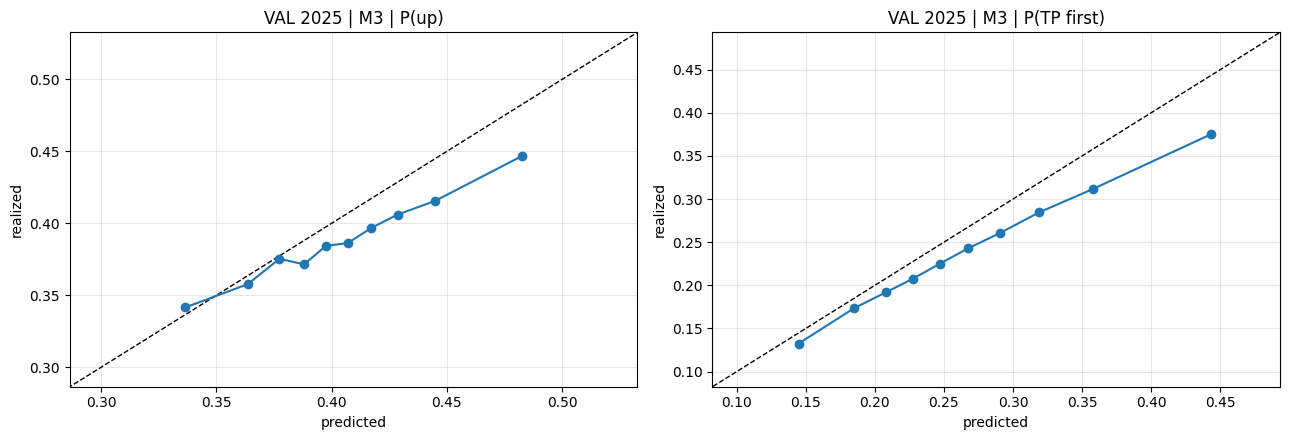

experiment log: 1 dev runs, 0 test runs


In [11]:
val_mask = ((DATA['ts'] >= pd.Timestamp(VAL_START, tz='UTC')) & (DATA['ts'] < pd.Timestamp(TEST_START, tz='UTC'))).to_numpy()
run_period(TO_VAL, VAL_START, TEST_START, FR)
VAL_EVAL = eval_table('dev', DATA, TO_VAL, val_mask, 'val')
display(VAL_EVAL.round(4))
val_score = VAL_EVAL[VAL_EVAL.model != 'M0'].groupby('model')['skill_vs_M0_%'].mean().sort_values(ascending=False)
CHOSEN = val_score.index[0]
print('CHOSEN (validation):', CHOSEN, '| mean skill vs M0 = %.3f%%' % val_score.iloc[0])
if val_score.iloc[0] <= 0:
    print('NOTE: no arm beats M0 on validation -> the features add nothing over the volatility regime. '
          'That is an honest, useful result.')
SIG_VAL = signal_table('dev', DATA, CHOSEN, val_mask, 'val')
print('\n"When the model said >= threshold, how often was it right?" (validation 2025)')
display(SIG_VAL.round(3))
calibration_plot('dev', DATA, CHOSEN, val_mask, 'VAL 2025')
log_run('val', {'skill': val_score.round(4).to_dict(), 'chosen': CHOSEN})
runs = [json.loads(x) for x in LOG.read_text().splitlines()]
print(f"experiment log: {sum(r['kind'] == 'dev' for r in runs)} dev runs, {sum(r['kind'] == 'test' for r in runs)} test runs")

## ۱۱) تست نهایی قفل (۲۰۲۶ + ارزهای جدید) — فقط یک بار

وقتی همه انتخاب‌ها انجام شد، `RUN_FINAL_TEST = True` و دوباره Run all. مدل فقط روی ۵ ارز اصلی آموزش می‌بیند و روی **۶ ارز جدید** هم سنجیده می‌شود. اگر روی ارزهای جدید هم از M0 بهتر باشد، الگو کلی است و فقط BTC را حفظ نکرده.

In [12]:
if not RUN_FINAL_TEST:
    print('Test is LOCKED. Set RUN_FINAL_TEST = True once, after freezing every choice.')
else:
    prev = [r for r in (json.loads(x) for x in LOG.read_text().splitlines()) if r['kind'] == 'test']
    if prev:
        print(f'WARNING: test already evaluated {len(prev)} time(s); it is no longer independent.')
    FR_T = {'dev': DATA, 'new': NEW}
    end = max(DATA['ts'].max(), NEW['ts'].max()) + pd.Timedelta(minutes=1)
    run_period([CHOSEN], TEST_START, end, FR_T)
    tmask_dev = (DATA['ts'] >= pd.Timestamp(TEST_START, tz='UTC')).to_numpy()
    tmask_new = (NEW['ts'] >= pd.Timestamp(TEST_START, tz='UTC')).to_numpy()
    TEST_EVAL = pd.concat([eval_table('dev', DATA, [CHOSEN], tmask_dev, 'test: dev coins'),
                           eval_table('new', NEW, [CHOSEN], tmask_new, 'test: NEW coins')])
    display(TEST_EVAL.round(4))
    for fname, frame, msk in (('dev', DATA, tmask_dev), ('new', NEW, tmask_new)):
        print(f'\nSignals - test {fname} coins'); display(signal_table(fname, frame, CHOSEN, msk, 'test').round(3))
        calibration_plot(fname, frame, CHOSEN, msk, f'TEST {fname}')
    t_sk = TEST_EVAL[TEST_EVAL.model == CHOSEN]
    log_run('test', {'chosen': CHOSEN, 'skill': {f'{r.period} | {r.target}': round(r['skill_vs_M0_%'], 4)
                                                 for _, r in t_sk.iterrows()}})
    TEST_EVAL.to_csv(RES / 'test_eval.csv', index=False)

Test is LOCKED. Set RUN_FINAL_TEST = True once, after freezing every choice.


## ۱۲) پیش‌بینی زنده: خروجی به همان شکلی که می‌خواستید

مدل انتخاب‌شده با ۳۶۵ روز آخر آموزش می‌بیند و برای آخرین لحظه موجود هر ارز، احتمال هر بازه درصدی و احتمال سد سه‌گانه را نشان می‌دهد.

In [13]:
now = DATA['ts'].max() + pd.Timedelta(minutes=1)
live_frames = {'dev': DATA} if NEW is None else {'dev': DATA, 'new': NEW}
fm_b, fm_r = fit_models(CHOSEN, 'y_bucket', now), fit_models(CHOSEN, 'y_barrier', now)
for fname, frame in live_frames.items():
    last_idx = frame.groupby('coin')['ts'].idxmax().to_numpy()
    rows = np.zeros(len(frame), bool); rows[last_idx] = True
    pb, _ = predict(fm_b, frame, rows); pr, _ = predict(fm_r, frame, rows)
    sub = frame.loc[rows]
    for i, (_, r) in enumerate(sub.iterrows()):
        sH = float(r['sigH'])
        edges_pct = [(np.exp(z * sH) - 1) * 100 for z in Z_EDGES]
        labels = [f'< {edges_pct[0]:+.2f}%'] + [f'{a:+.2f}% .. {b:+.2f}%' for a, b in zip(edges_pct[:-1], edges_pct[1:])] + [f'> {edges_pct[-1]:+.2f}%']
        print(f"\n{r['coin']} | {r['ts']} | price {r['close']:.6g} | next {HORIZON_MIN} min | model {CHOSEN}")
        display(pd.DataFrame({'range': labels, 'probability': np.round(pb[i], 3)}))
        tp, sl = (np.exp(K_UP * sH) - 1) * 100, (np.exp(-K_DN * sH) - 1) * 100
        print(f"   P(up >{edges_pct[3]:+.2f}%)={pb[i][UP].sum():.3f}  P(down <{edges_pct[2]:+.2f}%)={pb[i][DN].sum():.3f}")
        print(f"   barrier: P(hit {tp:+.2f}% first)={pr[i][2]:.3f} | P(hit {sl:+.2f}% first)={pr[i][0]:.3f} | P(neither)={pr[i][1]:.3f}")


BTC | 2026-11-19 00:00:00+00:00 | price 63068.2 | next 7 min | model M3


,range,probability
0,< -0.29%,0.053
1,-0.29% .. -0.14%,0.149
2,-0.14% .. -0.05%,0.189
3,-0.05% .. +0.05%,0.202
4,+0.05% .. +0.14%,0.174
5,+0.14% .. +0.29%,0.173
6,> +0.29%,0.060


   P(up >+0.05%)=0.407  P(down <-0.05%)=0.391
   barrier: P(hit +0.19% first)=0.386 | P(hit -0.19% first)=0.288 | P(neither)=0.325

ETH | 2026-11-19 00:00:00+00:00 | price 1777.19 | next 7 min | model M3


,range,probability
0,< -0.35%,0.045
1,-0.35% .. -0.17%,0.111
2,-0.17% .. -0.06%,0.229
3,-0.06% .. +0.06%,0.203
4,+0.06% .. +0.17%,0.218
5,+0.17% .. +0.35%,0.133
6,> +0.35%,0.060


   P(up >+0.06%)=0.411  P(down <-0.06%)=0.385
   barrier: P(hit +0.23% first)=0.367 | P(hit -0.23% first)=0.270 | P(neither)=0.363

SOL | 2026-11-19 00:00:00+00:00 | price 73.64 | next 7 min | model M3


,range,probability
0,< -0.35%,0.056
1,-0.35% .. -0.18%,0.151
2,-0.18% .. -0.06%,0.211
3,-0.06% .. +0.06%,0.194
4,+0.06% .. +0.18%,0.173
5,+0.18% .. +0.35%,0.136
6,> +0.35%,0.079


   P(up >+0.06%)=0.388  P(down <-0.06%)=0.418
   barrier: P(hit +0.23% first)=0.374 | P(hit -0.23% first)=0.262 | P(neither)=0.364

BNB | 2026-11-19 00:00:00+00:00 | price 582.71 | next 7 min | model M3


,range,probability
0,< -0.25%,0.059
1,-0.25% .. -0.12%,0.147
2,-0.12% .. -0.04%,0.172
3,-0.04% .. +0.04%,0.225
4,+0.04% .. +0.12%,0.179
5,+0.12% .. +0.25%,0.151
6,> +0.25%,0.067


   P(up >+0.04%)=0.397  P(down <-0.04%)=0.378
   barrier: P(hit +0.16% first)=0.374 | P(hit -0.16% first)=0.322 | P(neither)=0.304

XRP | 2026-11-19 00:00:00+00:00 | price 0.9677 | next 7 min | model M3


,range,probability
0,< -0.35%,0.041
1,-0.35% .. -0.17%,0.125
2,-0.17% .. -0.06%,0.168
3,-0.06% .. +0.06%,0.220
4,+0.06% .. +0.17%,0.223
5,+0.17% .. +0.35%,0.171
6,> +0.35%,0.053


   P(up >+0.06%)=0.447  P(down <-0.06%)=0.333
   barrier: P(hit +0.23% first)=0.435 | P(hit -0.23% first)=0.236 | P(neither)=0.330


## ۱۳) کدام ابزار بیشترین وزن را داشت؟

اهمیت ویژگی‌ها (gain) در مدل زنده، جمع‌شده بر اساس گروه و تایم‌فریم. این نشان می‌دهد مدل برای تصمیم‌گیری بیشتر به کدام سبک تکیه کرده است.


bucket: importance by group
b        0.472
p_1h     0.175
p_5m     0.164
p_15m    0.161
p        0.027


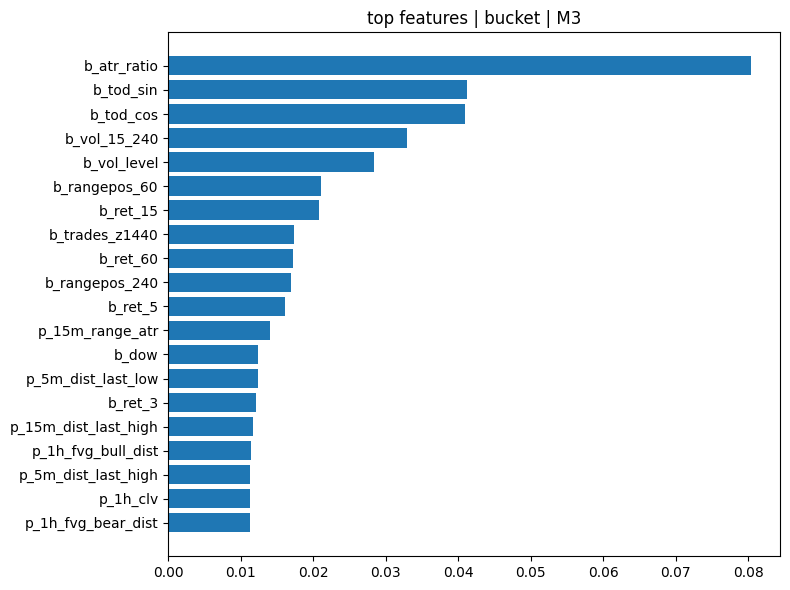


barrier: importance by group
b        0.557
p_1h     0.148
p_15m    0.143
p_5m     0.127
p        0.025


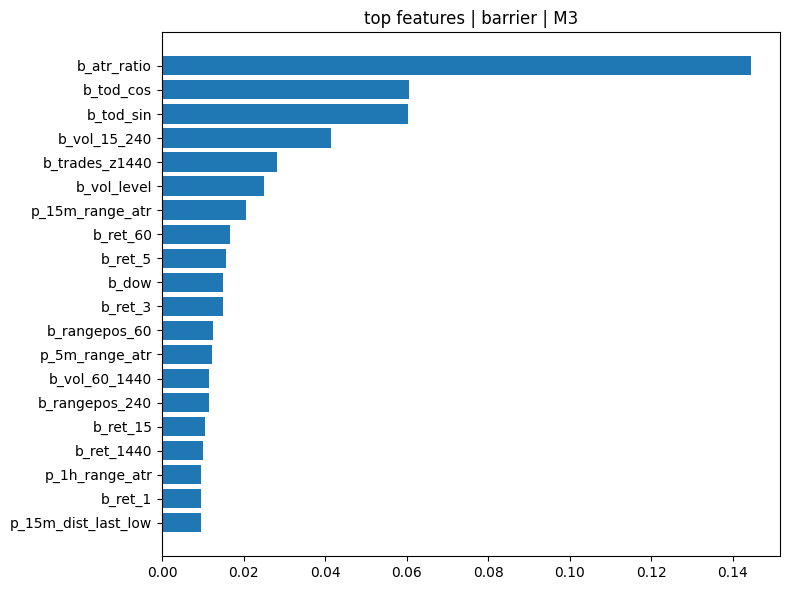

saved to /content/ta_prob_v2/results


In [14]:
for name, fm in (('bucket', fm_b), ('barrier', fm_r)):
    imp = pd.Series(fm['model'].booster_.feature_importance('gain'), index=fm['cols'])
    imp = imp / imp.sum()
    group = imp.groupby(lambda c: c.split('_')[0] + ('_' + c.split('_')[1] if c.split('_')[1] in ('5m', '15m', '1h') else '')).sum()
    print(f'\n{name}: importance by group'); print(group.sort_values(ascending=False).round(3).to_string())
    top = imp.sort_values(ascending=False).head(20)[::-1]
    plt.figure(figsize=(8, 6)); plt.barh(list(top.index), top.to_numpy()); plt.title(f'top features | {name} | {CHOSEN}')
    plt.tight_layout(); plt.show()
DEV_EVAL.to_csv(RES / 'dev_eval.csv', index=False); VAL_EVAL.to_csv(RES / 'val_eval.csv', index=False)
SIG_VAL.to_csv(RES / 'val_signals.csv', index=False)
print('saved to', RES)

## ۱۴) نتیجه را چطور بخوانیم

- **`skill_vs_M0_%` مثبت با فاصله اطمینانی که صفر را شامل نشود:** مدل واقعاً از «فراوانی تاریخی» بهتر است. در این مسئله حتی ۱ تا ۳ درصد هم قابل توجه است.
- **مقایسه M2 و M3 با M1:** جواب عددی به سؤال «آیا خط روند / پرایس اکشن کمک می‌کند؟».
- **جدول سیگنال:** مثلاً «آستانه 0.60، signal_share 3٪، hit_rate 0.61، base_rate 0.40» یعنی مدل ۳٪ وقت‌ها با اطمینان ۶۰٪ یا بیشتر سیگنال داده و ۶۱٪ این سیگنال‌ها درست بوده، در حالی که بدون مدل فقط ۴۰٪ وقت‌ها این اتفاق می‌افتد.
- **اگر هیچ مدلی از M0 بهتر نبود:** با این ویژگی‌ها و این افق مزیتی وجود ندارد. می‌توانید افق دیگری را امتحان کنید (`HORIZON_MIN = 15` یا `60`)، ولی هر امتحان در لاگ ثبت می‌شود.